# 9. The filter law

A theory of the size–volatility law in two steps, on the two reference economies of each graph.

1. **At current size, a firm low-pass filters its market at a rate equal to its size.** Linearised around its current
   size $S$, the log of the one-firm equation relaxes at the rate $S$ (self-limitation) and is driven by the motion of
   the field and by the demographic noise. The growth over a horizon $\tau$ then has the variance
   $$v^2(S,\tau)=\langle f^2\rangle_S\,G(S,\tau)+\frac{D\,(1-e^{-S\tau})}{S^2},\qquad
   G(S,\tau)=\int\frac{d\omega}{2\pi}\,\hat\rho(\omega)\,\frac{2(1-\cos\omega\tau)}{S^2+\omega^2},$$
   with $f$ the temporal amplitude of a node's field and $\hat\rho$ the spectrum of the field's correlation. A small
   firm relaxes slowly and integrates its market ($G\to$ the field summed over $\tau$, the same at every size); a
   large one follows its market and resists it ($G\to2[1-\rho(\tau)]/S^2$). The law is the crossover. Nothing is
   fitted; the horizon is a variable of the law, not a choice of the analyst.
2. **A life's volatility is that law averaged over the life.** The panel of MSB conditions on the life-mean size. A
   life's squared volatility is dominated by the years it spent small (the climb after birth, the dips), where the
   law gives a high volatility; its mean size is dominated by the years it spent large. So the curve against mean
   size is much flatter than the curve against current size.

The volatility is the growth standard deviation throughout (the panel's MAD estimator gives slightly different
ratios). Sizes are relative sizes $S=x/m$; one sampling step, $0.5$ time units, is the paper's year.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import economy as eco
from economy import D, DT, zeta_bins

MAXLAG = 120
f2 = lambda a: " ".join(f"{x:5.2f}" for x in a)
zeta = lambda Sb, x: zeta_bins(Sb, x)[0]
TAUS = (1, 2, 4)                                         # horizons in sampling steps: 0.5, 1, 2 time units


def mean_acf(x, T):
    """Network-mean autocorrelation of normalised paths x (rows), lags 0..MAXLAG-1 samples, cut at the first zero."""
    ac = np.array([np.mean(np.sum(x[:, l:] * x[:, :T - l], 1)) / T for l in range(MAXLAG)])
    ac /= ac[0]
    if (ac < 0).any():
        ac[np.argmax(ac < 0):] = 0
    return ac


def G_of(acf, h, tau, dt=0.05):
    """2[C(0) - C(tau)] for y' = -h y + xi, with xi of unit variance and correlation acf (lags of DT), from the spectrum."""
    lag = np.arange(0, MAXLAG * DT, dt)
    rho = np.interp(lag, np.arange(acf.size) * DT, acf, right=0.0)
    M = 1 << 16
    r = np.zeros(M); r[:lag.size] = rho; r[M - lag.size + 1:] = rho[1:][::-1]
    spec = np.clip(np.fft.rfft(r).real, 0, None) * dt
    w = 2 * np.pi * np.fft.rfftfreq(M, dt)
    wt = np.where((w == 0) | (w == w[-1]), 1.0, 2.0)     # weights of the half spectrum
    return np.array([(wt * spec * 2 * (1 - np.cos(w * tau)) / (hh ** 2 + w ** 2)).sum() * (w[1] - w[0]) / (2 * np.pi)
                     for hh in np.atleast_1d(h)])


def load(kind):
    """Sizes, death counters, each node's field amplitude and the field's correlation, for both reference economies."""
    out = []
    for seed in eco.SEEDS:
        S, L, deg, a, Phi = eco.reference_economy(seed, kind)
        f = Phi.std(1)
        out.append((S, L, f, mean_acf((Phi - Phi.mean(1)[:, None]) / f[:, None], S.shape[1])))
    return out


ECON = {kind: load(kind) for kind in ("powerlaw", "regular")}
ACF = {kind: np.mean([e[3] for e in ECON[kind]], 0) for kind in ECON}
print("field correlation after one year: " + ", ".join(f"{k} {ACF[k][1]:.3f}" for k in ACF))

field correlation after one year: powerlaw 0.941, regular 0.957


## 1. The law at current size

For every firm alive at $t$ and still alive at $t+\tau$ (the same life), the growth $\ln S(t+\tau)-\ln S(t)$, binned
by the current size $S(t)$. In brackets the filter law, with $\langle f^2\rangle_S$ the mean squared field amplitude of
the firms in the bin. Below $S\simeq0.15$ the firms are newborns, and those that survive the horizon are a small
selected group (the law does not apply there).

In [2]:
EDGES = np.logspace(np.log10(0.05), np.log10(10), 18)
C = np.sqrt(EDGES[1:] * EDGES[:-1])
CUR = {}
for kind, econ in ECON.items():
    rows = {}
    for k in TAUS:
        b_, d_, f_ = [], [], []
        for S, L, f, _ in econ:
            ok = L[:, :-k] == L[:, k:]
            b = np.digitize(S[:, :-k][ok], EDGES) - 1
            g = (b >= 0) & (b < C.size)
            b_.append(b[g]); d_.append(np.log(S[:, k:] / S[:, :-k])[ok][g]); f_.append(np.broadcast_to(f[:, None], ok.shape)[ok][g])
        b, d, ff = np.concatenate(b_), np.concatenate(d_), np.concatenate(f_)
        n = np.bincount(b, minlength=C.size)
        dc = d - (np.bincount(b, weights=d, minlength=C.size) / n)[b]
        mom = np.array([np.bincount(b, weights=np.abs(dc) ** q, minlength=C.size) / n for q in (1, 2, 3, 4)])
        tau = DT * k
        law = np.sqrt(np.bincount(b, weights=ff ** 2, minlength=C.size) / n * G_of(ACF[kind], C, tau)
                      + D * (1 - np.exp(-C * tau)) / C ** 2)
        rows[k] = (np.sqrt(mom[1]), law, mom)
    CUR[kind] = rows
    print(f"{kind}: growth sd at current size, filter law in brackets")
    print("     S   " + "".join(f"       tau = {DT * k:<4}  " for k in TAUS))
    for i in range(C.size):
        print(f"  {C[i]:6.3f} " + "".join(f"   {rows[k][0][i]:.3f} ({rows[k][1][i]:.3f})" for k in TAUS))
    sel = (C >= 0.3) & (C <= 8)
    for k in TAUS:
        sim, law, mom = rows[k]
        lx = np.log(C[sel])
        zq = np.array([-np.polyfit(lx, np.log(mom[q][sel]), 1)[0] for q in range(4)])
        print(f"  tau {DT * k}: slope for 0.3 <= S <= 8: simulation {zq[0] / 1:.2f} (zeta_q {f2(zq)}, ratios {f2(zq[1:] / zq[0])}),"
              f" law {-np.polyfit(lx, np.log(law[sel]), 1)[0]:.2f}")
    print()

powerlaw: growth sd at current size, filter law in brackets
     S          tau = 0.5          tau = 1.0          tau = 2.0   
   0.058    1.345 (1.250)   1.490 (2.049)   1.723 (3.525)
   0.080    1.324 (1.131)   1.499 (1.879)   1.718 (3.259)
   0.109    1.258 (1.016)   1.496 (1.720)   1.713 (3.005)
   0.149    0.993 (0.894)   1.414 (1.553)   1.676 (2.729)
   0.203    0.820 (0.802)   1.316 (1.406)   1.625 (2.462)
   0.278    0.702 (0.714)   1.211 (1.262)   1.567 (2.196)
   0.379    0.611 (0.629)   1.092 (1.114)   1.495 (1.923)
   0.518    0.531 (0.545)   0.960 (0.967)   1.402 (1.652)
   0.707    0.455 (0.465)   0.822 (0.822)   1.277 (1.385)
   0.966    0.384 (0.390)   0.688 (0.684)   1.132 (1.135)
   1.319    0.317 (0.323)   0.562 (0.559)   0.971 (0.910)
   1.801    0.259 (0.264)   0.456 (0.451)   0.818 (0.720)
   2.460    0.212 (0.216)   0.372 (0.363)   0.684 (0.570)
   3.359    0.175 (0.178)   0.309 (0.295)   0.580 (0.457)
   4.588    0.150 (0.149)   0.266 (0.247)   0.507 (0.378)
   

regular: growth sd at current size, filter law in brackets
     S          tau = 0.5          tau = 1.0          tau = 2.0   
   0.058    1.349 (1.074)   1.436 (1.694)   1.571 (2.800)
   0.080    1.341 (0.946)   1.449 (1.514)   1.575 (2.540)
   0.109    1.295 (0.832)   1.447 (1.349)   1.578 (2.290)
   0.149    0.981 (0.729)   1.333 (1.195)   1.547 (2.044)
   0.203    0.729 (0.635)   1.177 (1.049)   1.500 (1.801)
   0.278    0.581 (0.550)   1.017 (0.911)   1.428 (1.560)
   0.379    0.484 (0.471)   0.856 (0.779)   1.334 (1.325)
   0.518    0.410 (0.400)   0.706 (0.656)   1.200 (1.103)
   0.707    0.345 (0.336)   0.576 (0.544)   1.024 (0.899)
   0.966    0.286 (0.279)   0.463 (0.443)   0.827 (0.716)
   1.319    0.233 (0.229)   0.367 (0.356)   0.635 (0.560)
   1.801    0.188 (0.186)   0.287 (0.282)   0.476 (0.432)
   2.460    0.150 (0.150)   0.223 (0.220)   0.355 (0.329)
   3.359    0.120 (0.120)   0.171 (0.170)   0.264 (0.249)
   4.588    0.094 (0.094)   0.131 (0.131)   0.197 (0.189)
   6

The law follows the simulation to a few per cent for established firms up to $\tau=1$ on the power-law graph and up
to $\tau=2$ on the regular graph. At $\tau=2$ on the power-law graph the firms move too far for linear response.

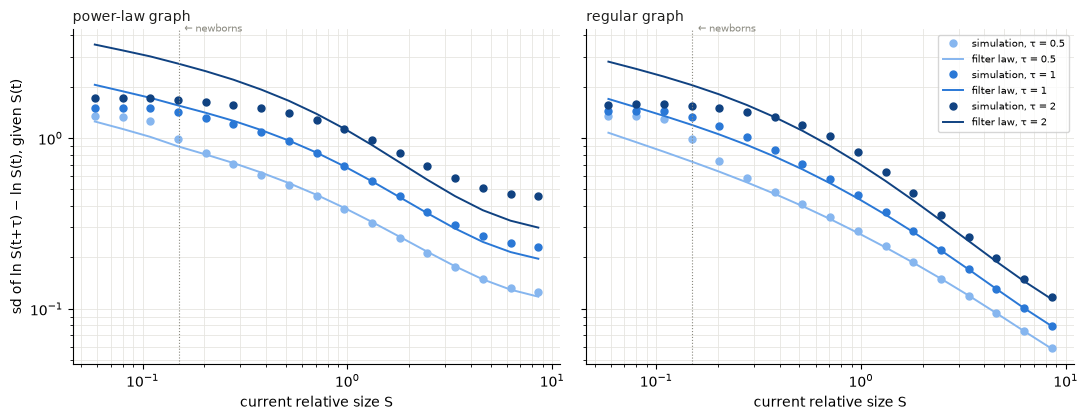

In [3]:
ORD = {1: "#86b6ef", 2: "#2a78d6", 4: "#104281"}; INK, MUTED, GRID = "#1f1f1e", "#8a897f", "#e6e5e0"
fig, axs = plt.subplots(1, 2, figsize=(11, 4.3), sharey=True)
for ax, kind, title in zip(axs, ("powerlaw", "regular"), ("power-law graph", "regular graph")):
    for k in TAUS:
        sim, law, _ = CUR[kind][k]
        ax.plot(C, sim, "o", color=ORD[k], ms=5, label=f"simulation, τ = {DT * k:g}")
        ax.plot(C, law, "-", color=ORD[k], lw=1.4, label=f"filter law, τ = {DT * k:g}")
    ax.axvline(0.15, color=MUTED, lw=0.8, ls=":"); ax.text(0.16, 4.2, "← newborns", fontsize=7.5, color=MUTED)
    ax.set(xscale="log", yscale="log", xlabel="current relative size S")
    ax.set_title(title, loc="left", fontsize=10, color=INK); ax.grid(color=GRID, lw=0.6, which="both"); ax.set_axisbelow(True)
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)
axs[0].set_ylabel("sd of ln S(t+τ) − ln S(t), given S(t)"); axs[1].legend(fontsize=7.5, loc="upper right")
fig.tight_layout(); plt.show()

## 2. From current size to the life panel

For each life, the filter-law variance is evaluated at the size the firm had in each of its years ($\tau$ one year,
the node's field amplitude) and averaged over the life; the result is set against the life-mean size, as in the
panel of MSB. Nothing is fitted. The current-size slope of about 0.58 on the power-law graph becomes about 0.24, close
to the panel's 0.19: the life protocol is part of the law. The rest of the gap, the short lives and the top of the bend
are open (the life average ignores that firms which survive small have calmer fields than their node's average, and
the trend of growth within a life).

In [4]:
grid = np.logspace(-4, 1.5, 300)
for kind, econ in ECON.items():
    Gg = G_of(ACF[kind], grid, DT)
    rows = []
    for S, L, f, _ in econ:
        Gs = np.exp(np.interp(np.log(np.clip(S, 1e-4, 30)), np.log(grid), np.log(Gg)))
        var = f[:, None] ** 2 * Gs + D * (1 - np.exp(-S * DT)) / S ** 2
        T = S.shape[1]
        for i in range(S.shape[0]):
            for seg in np.split(np.arange(T), np.flatnonzero(np.diff(L[i])) + 1):
                if seg.size < 6:
                    continue
                g = np.diff(np.log(S[i, seg]))
                rows.append((S[i, seg].mean(), g.std(), g.size, var[i, seg[:-1]].mean()))
    Sb, sd, n, vf = np.array(rows).T
    print(f"{kind}: life panel against life-mean size, growth sd; filter law averaged over each life")
    for nmin in (20, 5):
        m = n >= nmin
        zs, zl = zeta(Sb[m], sd[m]), zeta(Sb[m], np.sqrt(vf[m]))
        lv = [np.sqrt(vf[m][p].mean() / (sd[m][p] ** 2).mean()) for p in np.array_split(np.argsort(Sb[m]), 5)]
        print(f"   lives >= {nmin:2d}: zeta_1 simulation {zs[0]:.3f}, law {zl[0]:.3f};  ratios {f2(zs[1:] / zs[0])} / {f2(zl[1:] / zl[0])};"
              f"  level law / simulation by fifth {f2(lv)}")

powerlaw: life panel against life-mean size, growth sd; filter law averaged over each life
   lives >= 20: zeta_1 simulation 0.190, law 0.241;  ratios  1.75  2.30  2.70 /  1.75  2.52  4.02;  level law / simulation by fifth  1.21  1.11  1.08  1.06  1.10


   lives >=  5: zeta_1 simulation 0.155, law 0.257;  ratios  1.98  2.90  3.75 /  1.87  2.71  3.79;  level law / simulation by fifth  1.47  1.23  1.12  1.05  1.03


regular: life panel against life-mean size, growth sd; filter law averaged over each life
   lives >= 20: zeta_1 simulation 0.397, law 0.461;  ratios  1.93  2.78  3.53 /  1.93  2.83  3.79;  level law / simulation by fifth  1.15  1.04  1.00  0.98  0.99


   lives >=  5: zeta_1 simulation 0.256, law 0.361;  ratios  2.07  3.19  4.34 /  1.98  3.10  4.50;  level law / simulation by fifth  1.44  1.20  1.08  1.00  0.98


## 3. What the life average needs: sorting

Firms of equal current size are not alike. Ranking lives by their mean size sorts them by their own field: a firm can
stay small for many years only if its field rarely dips, and lives that are large on average have rough fields. So the
volatility of a life is not the average volatility of the firms at the sizes it passed through. The table compares the
measured panel with four averages over each life: the filter law with the node's amplitude, with the life's own
amplitude (the standard deviation of its field over the life), and the measured current-size variance at the sizes the
life passed through. The last lines give the field amplitude over the life by decile of life-mean size, against the
slope of the node's amplitude with current size.

In [5]:
def life_rows(kind):
    """Per life (>= 5 growth rates): Sbar, growth sd, MAD v, n, filter law with the node's f, with the life's own f,
    measured current-size variance averaged over the life, the life's own f."""
    econ = ECON[kind]
    Gg = G_of(ACF[kind], grid, DT)
    E = np.logspace(-4, np.log10(30), 70); lc = np.log(np.sqrt(E[1:] * E[:-1]))
    b_, d_ = [], []
    for S, L, f, _ in econ:
        ok = L[:, :-1] == L[:, 1:]; b = np.digitize(S[:, :-1][ok], E) - 1; g = (b >= 0) & (b < lc.size)
        b_.append(b[g]); d_.append(np.log(S[:, 1:] / S[:, :-1])[ok][g])
    b, d = np.concatenate(b_), np.concatenate(d_); n = np.bincount(b, minlength=lc.size); okb = n >= 50
    m = np.bincount(b, weights=d, minlength=lc.size) / np.maximum(n, 1)
    vmeas = np.bincount(b, weights=d ** 2, minlength=lc.size) / np.maximum(n, 1) - m ** 2
    rows = []
    for seed, (S, L, f, _) in zip(eco.SEEDS, econ):
        Phi = eco.reference_economy(seed, kind)[4]
        Gs = np.exp(np.interp(np.log(np.clip(S, 1e-4, 30)), np.log(grid), np.log(Gg)))
        noise = D * (1 - np.exp(-S * DT)) / S ** 2
        T = S.shape[1]
        for i in range(S.shape[0]):
            for seg in np.split(np.arange(T), np.flatnonzero(np.diff(L[i])) + 1):
                if seg.size < 6:
                    continue
                x = S[i, seg]; g = np.diff(np.log(x)); y = seg[:-1]; fl = Phi[i, seg].std()
                rows.append((x.mean(), g.std(), np.sqrt(np.pi / 2) * np.abs(g - g.mean()).mean(), g.size,
                             (f[i] ** 2 * Gs[i, y] + noise[i, y]).mean(), (fl ** 2 * Gs[i, y] + noise[i, y]).mean(),
                             np.interp(np.log(x[:-1]), lc[okb], vmeas[okb]).mean(), fl))
    return np.array(rows)


PANEL = {kind: life_rows(kind) for kind in ECON}
for kind, R in PANEL.items():
    Sb, sd, v, n, vnode, vlife, vmeas, fl = R.T
    print(f"{kind}: life panel against life-mean size, growth sd (zeta_1, ratios, level against the measured by fifth)")
    for nmin in (20, 5):
        k = n >= nmin
        for lab, x in (("measured", sd[k] ** 2), ("filter law, node's f", vnode[k]), ("filter law, life's own f", vlife[k]),
                       ("measured current-size curve", vmeas[k])):
            z = zeta(Sb[k], np.sqrt(x)); lv = [np.sqrt(x[p].mean() / (sd[k][p] ** 2).mean()) for p in np.array_split(np.argsort(Sb[k]), 5)]
            print(f"   lives >= {nmin:2d}  {lab:28s} {z[0]:.3f}   {f2(z[1:] / z[0])}   {f2(lv)}")
    k = n >= 20
    print("   field amplitude over the life by decile of life-mean size (lives >= 20): "
          + f2([fl[k][p].mean() for p in np.array_split(np.argsort(Sb[k]), 10)]))
    S, L, f, _ = ECON[kind][0]
    alive = S > 0.3
    fs = np.broadcast_to(f[:, None], S.shape)[alive]
    print(f"   node amplitude against current size (S > 0.3): f ~ S^{np.polyfit(np.log(S[alive]), np.log(fs), 1)[0]:.2f}\n")

powerlaw: life panel against life-mean size, growth sd (zeta_1, ratios, level against the measured by fifth)
   lives >= 20  measured                     0.190    1.75  2.30  2.70    1.00  1.00  1.00  1.00  1.00
   lives >= 20  filter law, node's f         0.241    1.75  2.52  4.02    1.21  1.11  1.08  1.06  1.10


   lives >= 20  filter law, life's own f     0.217    1.78  2.84  5.06    1.03  0.95  0.93  0.92  0.97
   lives >= 20  measured current-size curve  0.370    1.92  2.77  3.54    1.28  1.15  1.07  1.00  0.86


   lives >=  5  measured                     0.155    1.98  2.90  3.75    1.00  1.00  1.00  1.00  1.00


   lives >=  5  filter law, node's f         0.257    1.87  2.71  3.79    1.47  1.23  1.12  1.05  1.03
   lives >=  5  filter law, life's own f     0.250    1.90  2.87  4.20    1.30  1.01  0.89  0.87  0.89


   lives >=  5  measured current-size curve  0.271    1.95  2.84  3.69    1.24  1.29  1.14  1.02  0.89
   field amplitude over the life by decile of life-mean size (lives >= 20):  0.70  0.84  0.94  1.03  1.12  1.22  1.32  1.45  1.65  2.24


   node amplitude against current size (S > 0.3): f ~ S^0.10

regular: life panel against life-mean size, growth sd (zeta_1, ratios, level against the measured by fifth)
   lives >= 20  measured                     0.397    1.93  2.78  3.53    1.00  1.00  1.00  1.00  1.00
   lives >= 20  filter law, node's f         0.461    1.93  2.83  3.79    1.15  1.04  1.00  0.98  0.99
   lives >= 20  filter law, life's own f     0.418    1.92  2.84  3.86    1.03  0.94  0.93  0.93  0.97


   lives >= 20  measured current-size curve  0.493    1.92  2.76  3.52    1.29  1.17  1.12  1.09  1.06
   lives >=  5  measured                     0.256    2.07  3.19  4.34    1.00  1.00  1.00  1.00  1.00


   lives >=  5  filter law, node's f         0.361    1.98  3.10  4.50    1.44  1.20  1.08  1.00  0.98
   lives >=  5  filter law, life's own f     0.352    1.98  3.14  4.61    1.35  1.07  0.95  0.88  0.92


   lives >=  5  measured current-size curve  0.325    1.94  2.82  3.66    1.23  1.33  1.28  1.15  1.09
   field amplitude over the life by decile of life-mean size (lives >= 20):  0.58  0.67  0.74  0.81  0.87  0.94  1.01  1.09  1.19  1.35


   node amplitude against current size (S > 0.3): f ~ S^0.02



## 4. Paper figure

(a), (b) Growth volatility at current size over three horizons, measured and from the filter law, on the power-law and
the regular graph. (c) The panel of MSB for lives with at least 20 growth rates: measured, and the filter law averaged
over each life with the life's own field amplitude (solid) or the node's (dashed).

'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


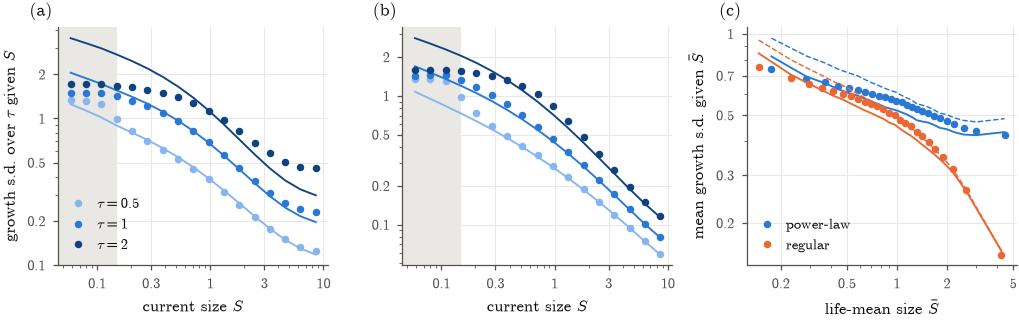

In [6]:
eco.paper_style()
fig, ax = plt.subplots(1, 3, figsize=(7.0, 2.35))
ORDP = {1: eco.FIFTHS[0], 2: eco.FIFTHS[2], 4: eco.FIFTHS[4]}
for a, kind, letter in ((ax[0], "powerlaw", "a"), (ax[1], "regular", "b")):
    for k in TAUS:
        sim, law, _ = CUR[kind][k]
        a.plot(C, sim, "o", ms=2.6, color=ORDP[k], label=fr"$\tau={DT * k:g}$")
        a.plot(C, law, "-", lw=0.9, color=ORDP[k])
    a.axvspan(0.045, 0.15, color=eco.PAL["grid"], lw=0)
    a.set(xscale="log", yscale="log", xlabel=r"current size $S$", xlim=(0.045, 11))
    eco.tidy(a, xticks=[0.1, 0.3, 1, 3, 10], yticks=[0.1, 0.2, 0.5, 1, 2]); eco.panel(a, letter)
ax[0].set_ylabel(r"growth s.d. over $\tau$ given $S$"); ax[0].legend(loc="lower left", handlelength=1)
cols = {"powerlaw": eco.PAL["model"], "regular": eco.PAL["regular"]}
for kind, R in PANEL.items():
    Sb, sd, v, n, vnode, vlife, vmeas, fl = R.T
    k = n >= 20; P = np.array_split(np.argsort(Sb[k]), 25); x = [Sb[k][p].mean() for p in P]
    ax[2].plot(x, [sd[k][p].mean() for p in P], "o", ms=2.6, color=cols[kind], label="power-law" if kind == "powerlaw" else "regular")
    ax[2].plot(x, [np.sqrt(vlife[k][p]).mean() for p in P], "-", lw=0.9, color=cols[kind])
    ax[2].plot(x, [np.sqrt(vnode[k][p]).mean() for p in P], "--", lw=0.7, color=cols[kind])
ax[2].set(xscale="log", yscale="log", xlabel=r"life-mean size $\bar S$", ylabel=r"mean growth s.d. given $\bar S$")
eco.tidy(ax[2], xticks=[0.2, 0.5, 1, 2, 5], yticks=[0.2, 0.3, 0.5, 0.7, 1]); eco.panel(ax[2], "c"); ax[2].legend(loc="lower left", handlelength=1)
fig.tight_layout(w_pad=0.8)
eco.save_paper(fig, "fig_filter"); plt.show()

## What is open

- **The rest of the life map.** The life average is too steep by about 0.05 for lives with at least 20 growth rates,
  and by about 0.10 for lives with at least five, whose level it overstates. Firms that survive small have calmer
  fields than their node's average, and the trend of growth within a life (the climb, the decline) is left out.
- **The top of the bend** on the power-law graph is too strong in the life average.
- **Long horizons.** At $\tau=2$ on the power-law graph the firms move too far for linear response.
- **The comparison with data.** The same conditioning on current size is measured in firm data (growth against
  initial size). If firm data give a similar slope against current and against mean size, while the model gives
  about 0.58 and 0.19, the model's firms move through sizes too much within a life.